# Plot simu vs. obs well data

In [1]:
import geopandas as gpd
from shapely.geometry import Point

In [2]:
%matplotlib inline
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 150

In [3]:
# %matplotlib notebook
# import glob, datetime, ipdb, pickle, pyproj, json, mplleaflet, geopandas, fiona, sys, cartopy, \
#          math, folium, base64
import glob, pickle, os
import numpy as np
import h5py as h5
import math
import pyproj

import matplotlib 
# matplotlib.use('Agg')
import matplotlib.pyplot as plt
# plt.style.use('seaborn-notebook')
import matplotlib.gridspec as gridspec
import matplotlib.dates as mdates

import pandas as pd
# import modin.pandas as pd
import ipywidgets as ipyw
# import cartopy.crs as ccrs
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
# import datetime
from datetime import timedelta, datetime
from scipy import interpolate
# from ipyleaflet import *
# from geojson import Feature, FeatureCollection, Point
from geopandas import GeoDataFrame
# from shapely.geometry import Point
from natsort import natsorted, ns, natsort_keygen
from sklearn.metrics import  mean_squared_error
# from folium.plugins import FloatImage
# from folium import IFrame

import re, lzma

# from tqdm import tqdm_notebook
from tqdm.notebook import tqdm

from pandas.plotting import register_matplotlib_converters
register_matplotlib_converters()

from myfunc import insertNA, printname, batch_delta_to_time, get_rmse
from modvis import utils

from fav_colors import fav_colors

from collections import Counter
import seaborn as sns

In [3]:
# from distributed import Client
# client = Client()

## I/O files and parameters (Pin code)

In [4]:
#=======================input==========================
# case_name = "AT-ugrid/TH-hete-bc/"

work_dir = "/pscratch/sd/p/pshuai/HFR-riverbed"
src_dir = "/global/cfs/cdirs/m1800/pin/HFR-riverbed"
case_name = "TH_perm_only_alluvium_2017-2019/"
# case_name = "perm_only_alluvium"
# model_dir = "../model_run/" + case_name
model_dir = os.path.join(work_dir, case_name)
# input_dir = "../model_run/inputs/"
input_dir = os.path.join(src_dir, "model_run", "inputs")
# big_data_dir = "../big_data/"
big_data_dir = "/global/cfs/cdirs/m1800/pin/github/HFR-thorne/big_data/"
# data_dir = "../data/"
data_dir = "/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/"
pickle_dir = os.path.join(src_dir, "output")
# figure_dir = "../figures/"
# fig_dir = "/global/project/projectdirs/pflotran/pin/AT-model/outputs/AT-20x10m/BTC/"
# out_dir = "../results/" + case_name
out_dir = os.path.join(src_dir, "output")
figure_dir = os.path.join(src_dir, "figures")

# # fname_model_origin = model_dir + "model_origin.txt"
# fname_material_h5 = model_dir + "AT_material_river.h5"

# fname_pflotran_h5 = model_dir + "AT-model-noAlluvium.h5"

# fname_300A_h5 = "/Users/shua784/Paraview/300A/John_case_optim_5/pflotran_bigplume-004.h5"

fname_tec_files = model_dir + "/" + "*.pft"
# fname_tec_files = model_dir + "AT-model-spinup-obs-*.tec"
fname_selected_wells = os.path.join( input_dir , "selected_well.txt")

# data_dir = "/global/project/projectdirs/m1800/pin/AT-model/data/"
fname_300A_well_data = big_data_dir + "observations/300A_wells_2008-2019.csv"
fname_WellScreen = data_dir + "well_obs/HEIS_300A_AT_well_screen.csv"
fname_test_well_data = os.path.join(big_data_dir, 'observations/temp_data_all_May-Nov_2019.csv')

# fname_optio2_data = data_dir + "chemistry/Processed_optio2_data_last10m_%O2.csv"
## riverbed temp
# HFR_data_dir = "/global/project/projectdirs/m1800/pin/HFR-thermal/data/"
fname_RG3_T = data_dir + "riverbed_temp/RG3_T3/300_Area_RG3_T3_Temps_20180502.csv"
fname_RG3_T_dat = data_dir + "riverbed_temp/RG3_T3/RG3_T3_Temps.dat"
fname_DA_T = data_dir + "riverbed_temp/DenseArray/DA1_CRiver_TM_T.csv"
fname_100H_dir = data_dir + "riverbed_temp/100H_thermistor_rods/"
iButton_dir = data_dir + 'riverbed_temp/iButton/'

fname_river_stage = big_data_dir + 'boundary_conditions/river_bc/stage_2007-2019/DatumH_River_321.txt'
fname_river_temp = big_data_dir + 'boundary_conditions/river_bc/temp_2007-2019/Temp_River_321.txt'


fname_simu_obs_head = out_dir + "simu_obs_head/"
fname_tracer_spc = out_dir + "tracer_spc/"
fname_head_tracer_spc = out_dir + "head_tracer_spc/"
fname_head_tracer_spc_temp = out_dir + "head_tracer_spc_temp/"
fname_simu_obs_temp = figure_dir + "simu_obs_temp/"

fname_simu_obs_chem = out_dir + "simu_obs_chem/"

# results_dir = "/global/project/projectdirs/m1800/pin/HFR-thorne/results/" + case_name

# fname_river_stage_plot = "/global/project/projectdirs/m1800/pin/AT-model/outputs/AT-ugrid/river_stage/"
# fname_river_temp_stage_plot = "/global/project/projectdirs/m1800/pin/AT-model/outputs/AT-ugrid/river_temp_stage/"

# input_dir = "/global/project/projectdirs/m1800/pin/HFR-thorne/inputs/"

In [5]:
# date_origin = datetime.strptime("2007-01-01 00:00:00", "%Y-%m-%d %H:%M:%S")
date_origin = datetime.strptime("2017-01-01 00:00:00", "%Y-%m-%d %H:%M:%S")
# model_origin = [594462.6688, 116280.5661] 

In [6]:
P_atm = 101325
rho = 997.16
g_const = 9.81

## import well data

In [8]:
# obs_data_df = pd.read_csv(fname_well_data, parse_dates=["DateTime"])
# fname_300A_well_data = '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/big_data/observations/300A_wells_2008-2019.csv'
obs_data_df = pd.read_csv(fname_300A_well_data)
# obs_data_df['DateTime'] = pd.to_datetime(obs_data_df['DateTime'],format='%m/%d/%y %H:%M:%S')
obs_data_df['DateTime'] = pd.to_datetime(obs_data_df['DateTime'],format='%Y-%m-%d %H:%M:%S')

In [9]:
print(obs_data_df.keys())
print(obs_data_df['WellName'])
print(obs_data_df['DateTime'])
print(obs_data_df.head)

Index(['DateTime', 'Temp', 'SpC', 'WL', 'WellName'], dtype='object')
0          399-1-1
1          399-1-1
2          399-1-1
3          399-1-1
4          399-1-1
            ...   
3357139      SWS-1
3357140      SWS-1
3357141      SWS-1
3357142      SWS-1
3357143      SWS-1
Name: WellName, Length: 3357144, dtype: object
0         2008-01-01 00:00:00
1         2008-01-01 01:00:00
2         2008-01-01 02:00:00
3         2008-01-01 03:00:00
4         2008-01-01 04:00:00
                  ...        
3357139   2019-12-31 19:00:00
3357140   2019-12-31 20:00:00
3357141   2019-12-31 21:00:00
3357142   2019-12-31 22:00:00
3357143   2019-12-31 23:00:00
Name: DateTime, Length: 3357144, dtype: datetime64[ns]
<bound method NDFrame.head of                    DateTime      Temp     SpC        WL WellName
0       2008-01-01 00:00:00  18.37000  0.3630  105.1907  399-1-1
1       2008-01-01 01:00:00  18.38000  0.3630  105.1835  399-1-1
2       2008-01-01 02:00:00  18.39000  0.3620  105.1763  399-1-1


In [10]:
obs_well_list = obs_data_df['WellName'].unique()
obs_well_list = ['Well_' + i for i in obs_well_list]

In [11]:
print(len(obs_data_df['DateTime'].unique()))

105183


In [12]:
print('total number of well data: {0}'.format(len(obs_well_list)))
obs_well_list

total number of well data: 50


['Well_399-1-1',
 'Well_399-1-10A',
 'Well_399-1-11',
 'Well_399-1-12',
 'Well_399-1-16A',
 'Well_399-1-17A',
 'Well_399-1-32',
 'Well_399-2-1',
 'Well_399-2-2',
 'Well_399-2-3',
 'Well_399-2-5',
 'Well_399-3-18',
 'Well_399-3-19',
 'Well_399-3-20',
 'Well_399-3-21',
 'Well_399-3-22',
 'Well_399-4-9',
 'Well_399-1-2',
 'Well_399-1-7',
 'Well_399-1-21A',
 'Well_399-1-23',
 'Well_399-2-10',
 'Well_399-3-26',
 'Well_399-5-1',
 'Well_399-6-1',
 'Well_399-8-1',
 'Well_399-1-15',
 'Well_399-1-60',
 'Well_399-2-33',
 'Well_399-3-29',
 'Well_399-3-34',
 'Well_399-3-37',
 'Well_399-4-7',
 'Well_399-8-5A',
 'Well_699-S19-E13',
 'Well_699-S19-E14',
 'Well_699-S27-E12A',
 'Well_699-S27-E14',
 'Well_699-S29-E13A',
 'Well_399-1-21B',
 'Well_399-1-57',
 'Well_399-2-25',
 'Well_399-2-32',
 'Well_SWS-1',
 'Well_399-3-9',
 'Well_399-3-10',
 'Well_NRG',
 'Well_699-S11-E12A',
 'Well_399-4-11',
 'Well_399-4-15']

In [13]:
# obs_data_df = pd.read_csv(fname_well_data, parse_dates=["DateTime"])
# fname_test_well_data = '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/big_data/observations/temp_data_all_May-Nov_2019.csv'
obs_df = pd.read_csv(fname_test_well_data)
# obs_data_df['DateTime'] = pd.to_datetime(obs_data_df['DateTime'],format='%m/%d/%y %H:%M:%S')
obs_df['DateTime'] = pd.to_datetime(obs_df['DateTime'],format='%Y-%m-%d %H:%M:%S')

### import river stage & temp

In [14]:
# downstream location MASS1-321
# fname_river_stage = '/global/homes/z/zc727/HFR/data/stage_2007-2019/DatumH_River_321.txt' # '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/big_data/boundary_conditions/river_bc/stage_2007-2019/DatumH_River_321.txt'
river_stage = pd.read_csv(fname_river_stage, header = None, sep = " ", 
                          names= ['dt', 'Easting', 'Northing', 'wl'])
river_stage['datetime'] = [date_origin + timedelta(seconds = i) for i in river_stage['dt'].values]
river_stage.set_index('datetime', drop = False, inplace = True)

In [15]:
# fname_river_temp ='/global/cfs/cdirs/m1800/pin/github/HFR-thorne/big_data/boundary_conditions/river_bc/temp_2007-2019/Temp_River_321.txt'
river_temp = pd.read_csv(fname_river_temp, header = None, sep = " ", 
                          names= ['dt', 'temp'])
river_temp['datetime'] = [date_origin + timedelta(seconds = i) for i in river_temp['dt'].values]
river_temp.set_index('datetime', drop = False, inplace = True)

### import well screen

In [16]:
# fname_WellScreen = '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/well_obs/HEIS_300A_AT_well_screen.csv'
well_screen = pd.read_csv(fname_WellScreen)

In [17]:
print(well_screen.keys())
print(well_screen.index)

Index(['Well_ID', 'WellName', 'Easting', 'Northing', 'CASING_ELEVATION',
       'SCREEN_ELEV_TOP', 'SCREEN_ELEV_BOTTOM'],
      dtype='object')
RangeIndex(start=0, stop=1024, step=1)


## export simulated head using observation files

We will import well observation from .tec outputs.

In [27]:
#pickle_dir = '/global/homes/z/zc727/HFR/output/'   #'/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/pickle/'
#case_name = "TH-heatBC-mesh_100m-rst1/"
#with lzma.open(pickle_dir + f"{case_name[:-1]}-well_data_df_ave.xz", 'rb') as f:
#    well_data_df = pd.read_pickle(f) #pickle.load(f)       

In [25]:
#print(well_data_df.keys())
#print(well_data_df.index)

MultiIndex([(    'RG3_T3_24cm',   'Liquid Pressure [Pa]',     'RG3_T3_24cm'),
            (    'RG3_T3_24cm',        'Temperature [C]',     'RG3_T3_24cm'),
            (    'RG3_T3_24cm', 'Total Tracer_river [M]',     'RG3_T3_24cm'),
            (    'RG3_T3_24cm',              'qlx [m/h]',     'RG3_T3_24cm'),
            (    'RG3_T3_24cm',              'qly [m/h]',     'RG3_T3_24cm'),
            (    'RG3_T3_64cm',   'Liquid Pressure [Pa]',     'RG3_T3_64cm'),
            (    'RG3_T3_64cm',        'Temperature [C]',     'RG3_T3_64cm'),
            (    'RG3_T3_64cm', 'Total Tracer_river [M]',     'RG3_T3_64cm'),
            (    'RG3_T3_64cm',              'qlx [m/h]',     'RG3_T3_64cm'),
            (    'RG3_T3_64cm',              'qly [m/h]',     'RG3_T3_64cm'),
            ...
            (  'Well_699-8-32', 'Total Tracer_river [M]', 'flux_ave_tracer'),
            (  'Well_699-8-32',        'Temperature [C]',   'flux_ave_temp'),
            ('iButton_B2_28cm', 'Total Tracer_ri

In [14]:
# simu_time = np.array([date_origin + timedelta(hours=i) for i in well_data_df.index])

In [ ]:
# with open(results_dir + "well_data_df.p", 'rb') as f:
#     well_data_df = pickle.load(f)

# with open(results_dir + "obs_pts_df.p", 'rb') as f:
#     obs_pts_df = pickle.load(f)

# with open(results_dir + "selected_obs_wells.p", 'rb') as f:
#     selected_obs_wells = pickle.load(f)

In [17]:
# fname_selected_wells = '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/model_run/inputs/selected_well.txt'
simu_well_list = pd.read_csv(fname_selected_wells,  header=None, names=['WellName'])
simu_well_list = simu_well_list['WellName'].values.tolist()

In [18]:
print('total number of simulation well: {0}'.format(len(simu_well_list)))
print('(unique)total number of simulation well: {0}'.format(len(np.unique(simu_well_list))))

total number of simulation well: 920
(unique)total number of simulation well: 920


In [ ]:
# simu_time = np.array([date_origin + timedelta(hours=i) for i in well_data_df.index])

### assemble all output data file

In [19]:
# with open(results_dir + "well_data_df-300A.p", 'rb') as f:
#     simu_time, well_data_df = pickle.load(f)

# with open(results_dir + "obs_pts_df.p", 'rb') as f:
#     obs_pts_df = pickle.load(f)

# with lzma.open(pickle_dir + f'{case_name[:-1]}-simu_data_df.xz', "rb") as f:
#    simu_data_df = pd.read_pickle(f)
    
with lzma.open(os.path.join(pickle_dir , f"{case_name[:-1]}-well_data_df_ave.xz"), 'rb') as f:
    well_data_df = pd.read_pickle(f)

In [25]:
#fname_tec_files = '/pscratch/sd/z/zc727/model_iso_perm/'+'*.pft'       # isotropic permeability
#fname_tec_files = '/pscratch/sd/z/zc727/model_aniso_perm_except_basalt/'+'*.pft'      # anisotropic permeability, except basalt
# fname_tec_files = '/pscratch/sd/z/zc727/model_aniso_perm_only_alluvium/'+'*.pft'       # anisotropic permeability, only alluvium
tec_files = glob.glob(fname_tec_files)
tec_files = natsorted(tec_files)
assert(len(tec_files) > 0),"No such files found in the specified directory."
# Optional: Print the sorted file list for verification
for file in tec_files:
    print(file)

/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-12.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-45.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-86.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-128.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-146.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-156.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-187.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-228.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-266.pft
/psc

This may take a while...

In [26]:
simu_data_df = pd.DataFrame()

for ifile in tqdm(tec_files[:]):   
# ifile = '/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium/TH_perm_only_alluvium-obs-96.pft'
    print(ifile)
    idf_header_row = pd.read_table(ifile, sep=',',header=None, nrows=1, engine='python')
    iheader = list(np.asarray(idf_header_row.values).flatten())
    idf = pd.read_table(ifile, sep='\s+',header=None, names=iheader, index_col=0, skiprows=1, engine='python')
    
    simu_data_df = pd.concat([simu_data_df, idf], axis=1, join='outer')

  0%|          | 0/57 [00:00<?, ?it/s]

/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-12.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-45.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-86.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-128.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-146.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-156.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-187.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-228.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-266.pft
/psc

In [51]:
# #interpret code by Chao
# sum = []
# for ifile in tqdm(tec_files[:]):   
# #     ifile = '/global/cscratch1/sd/pshuai/TH-100x100x2-thermal/TH_100x100x2_thermal-obs-1238.tec'
# #     print(ifile)
#     idf_header_row = pd.read_table(ifile, sep=',',header=None, nrows=1, engine='python')
#     iheader = list(np.asarray(idf_header_row.values).flatten())
#     idf = pd.read_table(ifile, sep='\s+',header=None, names=iheader, index_col=0, skiprows=1, engine='python')
#     print('file name: {0}, data number: {1}'.format(ifile,len(idf.columns)/6))
#     sum.append(len(idf.columns)/6)
# print('total data number: {0}'.format(np.sum(sum)))

In [57]:
# pickle_dir = '/global/homes/z/zc727/HFR/output/'
# case_name = "HFR-aniso_perm_only_alluvium/"                   # change to different name based on perm model used
# with lzma.open(pickle_dir + f'{case_name[:-1]}-simu_data_df.xz', "wb") as f:
#     pickle.dump(simu_data_df, f)

In [27]:
simu_time = np.array([date_origin + timedelta(hours=i) for i in simu_data_df.index])

In [28]:
simu_time

array([datetime.datetime(2017, 1, 1, 0, 0),
       datetime.datetime(2017, 1, 1, 6, 0),
       datetime.datetime(2017, 1, 1, 12, 0), ...,
       datetime.datetime(2019, 10, 31, 12, 0),
       datetime.datetime(2019, 10, 31, 18, 0),
       datetime.datetime(2019, 11, 1, 0, 0)], dtype=object)

In [29]:
print(f"total time points: {len(simu_time)}")

total time points: 4137


**import well list**

In [25]:
#selected_obs_wells = list(set(obs_well_list).intersection(simu_well_list))

In [27]:
print(simu_data_df.columns[:6])
print(len(simu_data_df.columns)/6)

Index(['Liquid Pressure [Pa] iButton_B2_8cm (11385) (5.9449E+05 1.1620E+05 107.301)',
       'Liquid Saturation iButton_B2_8cm (11385) (5.9449E+05 1.1620E+05 107.301)',
       'Temperature [C] iButton_B2_8cm (11385) (5.9449E+05 1.1620E+05 107.301)',
       'Total Tracer_river [M] iButton_B2_8cm (11385) (5.9449E+05 1.1620E+05 107.301)',
       'qlx [m/h] iButton_B2_8cm (11385) (5.9449E+05 1.1620E+05 107.301)',
       'qly [m/h] iButton_B2_8cm (11385) (5.9449E+05 1.1620E+05 107.301)'],
      dtype='object')
1955.3333333333333


In [30]:
obs_list = []
for icol in simu_data_df.columns:
    if icol.startswith('Liquid Pressure'):
        iname = re.split("\s", icol)[3] # split by space. e.g., 'Liquid', 'Pressure', '[Pa]', 'Well_399-2-1_1', '(241534)', '(5.9447E+05', '1.1612E+05', '109.4)'
        if iname.startswith('Well'):
            iname = 'Well_' + re.split("_", iname)[1]
        obs_list.append(iname)
        
obs_list = np.unique(np.array(obs_list))

In [ ]:
# # interpret code by Chao
# obs_list = []
# for icol in simu_data_df.columns:
#     if icol.startswith('Liquid Pressure'):
#         iname = re.split("\s", icol)[3] # split by space. e.g., 'Liquid', 'Pressure', '[Pa]', 'Well_399-2-1_1', '(241534)', '(5.9447E+05', '1.1612E+05', '109.4)'
#         if iname.startswith('Well'):
#             iname = 'Well_' + re.split("_", iname)[1]
#         obs_list.append(iname)

In [30]:
# print('the total number of observation well: {0}'.format(len(obs_list)))
# obs_list = np.unique(np.array(obs_list))
print('(unique) total number of observation well: {0}'.format(len(obs_list)))

(unique) total number of observation well: 456


**careful: double check to see if there is any ambiguity in the var names**

e.g., O2 laps with NO2 and CO2 when searching based on string `O2`

In [31]:
obs_var_names=['Liquid Pressure [Pa]', 'Temperature [C]', 'Total Tracer_river [M]', 'qlx [m/h]', 'qly [m/h]']
# obs_var_names=['Liquid Pressure [Pa]', 'Total Tracer_river [M]', 'qlx [m/h]', 'qly [m/h]']

# obs_var_names=['Liquid Pressure [Pa]', 'Total Tracer_river [M]', 
#                'qlx [m/h]', 'qly [m/h]']

### create dataframe to store obs.well point coordinates

Some wells show duplicated screens (e.g., well_screen1, well_screen2 have the same x,y,z coords), because PFLOTRAN snap the observation points to the nearest grid by default. 

See [observation_card](https://www.pflotran.org/documentation/user_guide/cards/subsurface/observation_card.html)

In [32]:
obs_point_name = []
obs_point_coordx = []
obs_point_coordy = []
obs_point_coordz = []
for iwell in obs_list[:]:
    
    # iwell = iwell[5:]
    # iwell = '399-1-86' 
    iobs = 'Liquid Pressure'
    
#     iwell_id = [iwell + '_' if '399' in iwell else iwell][0]
    if iwell.startswith('Well'):
        iwell += '_'
    # search for columns contain both iwell_id and iobs
    iwell_col_ind = [icol for icol in simu_data_df.columns if iwell in icol and icol.startswith(iobs)]
    
    # find obs coord
    for icol in iwell_col_ind:
        istr = re.split("\s", icol) # split by space. e.g., 'Liquid`, `Pressure', '[Pa]', 'Well_399-2-1_1', '(241534)', '(5.9447E+05', '1.1612E+05', '109.4)'
        obs_point_name.append(istr[3])  
        obs_point_coordx.append(float(istr[5].replace('(', '')))
        obs_point_coordy.append(float(istr[6]))
        obs_point_coordz.append(float(istr[7].replace(')', '')))    
# create a dataframe

arrays = np.vstack((np.array(obs_point_name), np.array(obs_point_coordx), 
                    np.array(obs_point_coordy), np.array(obs_point_coordz))).T

obs_pts_df = pd.DataFrame(arrays, index=arrays[:,0], columns=['obs_point', 'coord_x', 'coord_y', 'coord_z'])

obs_pts_df["coord_x"] = pd.to_numeric(obs_pts_df["coord_x"])
obs_pts_df["coord_y"] = pd.to_numeric(obs_pts_df["coord_y"])
obs_pts_df["coord_z"] = pd.to_numeric(obs_pts_df["coord_z"])

print('total number of observation well: {0}'.format(len(obs_pts_df.index)))

obs_pts_df = obs_pts_df.loc[~obs_pts_df.index.duplicated(keep='first')]

obs_pts_df 
print('(unique) total number of observation well: {0}'.format(len(obs_pts_df.index)))

total number of observation well: 1676
(unique) total number of observation well: 1676


In [33]:
# output the obs points 
with lzma.open(os.path.join(pickle_dir , f'{case_name[:-1]}-obs_pts_df.xz'), "wb") as f:
    pickle.dump(obs_pts_df, f)

### **create multiindex for dataframe**

column has three levels: well_name, variable_name, well_screen_name

Note: be careful that some well screen order may be reversed. Check `iwell_screen_array` to make sure it aligns with the order in `iwell_col_ind`.

In [36]:
# well_list_300A = [i for i in simu_well_list if '399' in i ]
# well_list = well_list_300A

# well_list = simu_well_list

well_list = obs_list

In [77]:
# iwell_name = 'Well_399-1-1'

In [37]:
well_array = []
var_array = []
well_screen_array = []

well_cols = []

## only search for a subset of wells
for iwell in tqdm(well_list[:]):
    print(iwell)
## search for all wells    
# for iwell in tqdm(obs_list[:]): 
# for iwell in ['399-1-1', '399-1-7', '399-1-60']:
    # iwell = 'T9_105.5_80cm'
    if iwell.startswith('Well'):
        iwell_id = iwell + '_'   
    else:
        iwell_id = iwell
    
    for iobs in obs_var_names[:]:
        # iobs = 'Liquid Pressure'
        
#         iwell_id = [iwell + '_' if '399' in iwell else iwell][0]

        # iwell_id = iwell + '_' # to differentiate 399-1-1 and 399-1-11
        # search for columns contain both iwell_id and iobs, double check if there is any ambiguity
        iwell_col_ind = [icol for icol in simu_data_df.columns if iwell_id in icol and icol.startswith(iobs)]                 
        # print(len(iwell_col_ind))
        
        # for wells with >1 screens
        if len(iwell_col_ind) > 1:
        
            # find well screens 
            iwell_screen_array = [re.search('Well(.+?)\ ', i).group(0)[:-1] for i in iwell_col_ind]
            # iwell_screen_array = [i.split()[-5] for i in iwell_col_ind] # count backwards b/c of the different spacings in variable names
            iwell_array = [iwell]*len(iwell_col_ind)
            ivar_array = [iobs]*len(iwell_col_ind)

            var_array += ivar_array
            well_array += iwell_array
            well_screen_array += iwell_screen_array

        # for piezometers or wells with only one screen
        elif len(iwell_col_ind) == 1:
            if 'Well' in iwell_col_ind[0]:
                # print(iwell_col_ind[0])
                well_screen_array += [iwell_id + '1'] 
            else:
                well_screen_array += [iwell] 
            var_array += [iobs]
            well_array += [iwell]

        else:
            continue
            
        well_cols += iwell_col_ind
        # see if there is duplicates
        dup_list = [item for item, count in Counter(well_cols).items() if count > 1]
        if len(dup_list) > 0:
            raise Exception('Duplicates:{} found in list!'.format(dup_list))

  0%|          | 0/456 [00:00<?, ?it/s]

RG3_T3_24cm
RG3_T3_64cm
T1_104.5_45cm
T1_104.5_60cm
T1_104_105cm
T1_104_50cm
T1_105.5_103.5cm
T1_105.5_53cm
T2_104.5_111cm
T2_104.5_35cm
T2_104_54.5cm
T2_104_55cm
T2_105.5_100cm
T2_105.5_52cm
T3_104.5_105cm
T3_104.5_50cm
T3_104_114cm
T3_104_50cm
T3_105.5_102cm
T3_105.5_50cm
T4_104.5_100cm
T4_104.5_200cm
T4_104.5_45cm
T4_104_104.5cm
T4_104_50cm
T4_105.5_200cm
T4_105.5_50cm
T4_105.5_54cm
T5_104.5_119cm
T5_104.5_203cm
T5_104.5_50cm
T5_104_113.5cm
T5_104_153cm
T5_104_46.5cm
T5_105.5_100cm
T5_105.5_200cm
T5_105.5_54cm
T6_104.5_100cm
T6_104.5_50cm
T6_104_105cm
T6_104_51.5cm
T6_105.5_46cm
T6_105.5_95cm
T7_104.5_100cm
T7_104.5_140cm
T7_104_102.5cm
T7_105.5_50cm
T7_105.5_93cm
T8_104.5_86cm
T8_104_105.5cm
T8_105.5_103cm
T9_105.5_80cm
Well_199-B2-12
Well_199-D5-13
Well_199-D5-14
Well_199-D8-4
Well_199-D8-5
Well_199-D8-55
Well_199-D8-6
Well_199-F7-2
Well_199-H3-2A
Well_199-H3-2B
Well_199-H3-2C
Well_199-H4-10
Well_199-H4-11
Well_199-H4-12A
Well_199-H4-12B
Well_199-H4-12C
Well_199-H4-13
Well_199-H4-

In [38]:
# print(well_screen_array[1003])
# print(well_array[1003])
# print(var_array[:4])
print(iwell_col_ind)

['qly [m/h] iButton_B2_8cm (11385) (5.9449E+05 1.1620E+05 107.301)']


In [39]:
arrays = [np.array(well_array), np.array(var_array), np.array(well_screen_array)]
index_col = pd.MultiIndex.from_arrays(arrays, names=('WellName', 'VariableName', 'WellInterval'))
well_data_df = pd.DataFrame(index=simu_data_df.index, columns=index_col)

This may take a long time to finish..

In [40]:
# for iwell in tqdm(well_list[:]):
for iwell in tqdm(well_data_df.columns.levels[0]):
#     print(iwell)
    # iwell = iwell[5:]
    if iwell.startswith('Well'):
        iwell_id = iwell + '_'   
    else:
        iwell_id = iwell
    for iobs in obs_var_names:
#         iwell_id = [iwell + '_' if '399' in iwell else iwell][0]

        # search for columns contain both iwell_id and iobs
        iwell_col_ind = [icol for icol in simu_data_df.columns if iwell_id in icol and icol.startswith(iobs)] 
        # iwell_screen_array = [re.search('Well(.+?)\ ', i).group(0)[:-1] for i in iwell_col_ind]
        iwell_screen_array = [i.split()[-5] for i in iwell_col_ind]
        for i in np.arange(len(iwell_col_ind))[:]:
            well_data_df[iwell, iobs, iwell_screen_array[i]] = simu_data_df[iwell_col_ind[i]].values

well_data_df = well_data_df.sort_index(axis=1)

  0%|          | 0/456 [00:00<?, ?it/s]

In [41]:
well_data_df

WellName              RG3_T3_24cm                                         \
VariableName Liquid Pressure [Pa] Temperature [C] Total Tracer_river [M]   
WellInterval          RG3_T3_24cm     RG3_T3_24cm            RG3_T3_24cm   
 "Time [h]"                                                                
0.0                      99857.12        16.80000           1.000000e-20   
6.0                     101805.50        16.79975           3.753151e-05   
12.0                    101734.10        16.79919           1.204398e-04   
18.0                    101912.60        16.79875           1.991773e-04   
24.0                    104982.90        11.23641           6.474134e-01   
...                           ...             ...                    ...   
24792.0                  92871.37        14.77762           5.467278e-01   
24798.0                  93810.51        14.77643           5.353561e-01   
24804.0                  94560.39        14.77470           5.263045e-01   
24810.0                  93855.60        14.77175           5.313766e-01   
24816.0                  92983.12        14.76871           5.375424e-01   

WellName                                      RG3_T3_64cm                  \
VariableName   qlx [m/h]   qly [m/h] Liquid Pressure [Pa] Temperature [C]   
WellInterval RG3_T3_24cm RG3_T3_24cm          RG3_T3_64cm     RG3_T3_64cm   
 "Time [h]"                                                                 
0.0             0.000000    0.000000            104412.40        16.80000   
6.0            -0.000402   -0.000625            106360.90        16.80002   
12.0           -0.000128   -0.000398            106289.40        16.80000   
18.0           -0.000216   -0.000316            106468.00        16.79995   
24.0           -0.000671   -0.000430            109056.50        16.56465   
...                  ...         ...                  ...             ...   
24792.0         0.000016    0.000006             97215.13        14.74658   
24798.0        -0.000291   -0.000117             98484.98        14.74131   
24804.0        -0.000017   -0.000005             99081.71        14.73784   
24810.0         0.000027    0.000011             98240.13        14.73847   
24816.0         0.000016    0.000007             97354.25        14.73881   

WellName                                                     ...  \
VariableName Total Tracer_river [M]   qlx [m/h]   qly [m/h]  ...   
WellInterval            RG3_T3_64cm RG3_T3_64cm RG3_T3_64cm  ...   
 "Time [h]"                                                  ...   
0.0                    1.000000e-20    0.000000    0.000000  ...   
6.0                    3.920532e-07   -0.000400   -0.000256  ...   
12.0                   3.433287e-06   -0.000158   -0.000096  ...   
18.0                   8.592570e-06   -0.000237   -0.000153  ...   
24.0                   6.036729e-02   -0.000663   -0.000139  ...   
...                             ...         ...         ...  ...   
24792.0                4.645600e-01    0.000171    0.000069  ...   
24798.0                4.561614e-01   -0.000240   -0.000097  ...   
24804.0                4.514775e-01   -0.000026   -0.000010  ...   
24810.0                4.548757e-01    0.000169    0.000068  ...   
24816.0                4.591519e-01    0.000169    0.000068  ...   

WellName          iButton_B2_88cm                                         \
VariableName Liquid Pressure [Pa] Temperature [C] Total Tracer_river [M]   
WellInterval      iButton_B2_88cm iButton_B2_88cm        iButton_B2_88cm   
 "Time [h]"                                                                
0.0                      92729.22        16.80000           1.000000e-20   
6.0                      94297.38        16.80280           2.200610e-06   
12.0                     94577.02        16.80322           1.597038e-05   
18.0                     94599.87        16.80316           4.243532e-05   
24.0                     96172.06        16.80517           1.154068e-03  

In [69]:
# with open(pickle_dir + "300A_well_simu_data_df.p", 'wb') as f:
#     pickle.dump((simu_time, well_data_df), f, protocol=-1)

# with open(pickle_dir + "300A_obs_pts_df.p", 'wb') as f:
#     pickle.dump(obs_pts_df, f, protocol=-1)

# with lzma.open(pickle_dir + f'{case_name[:-1]}-well_data_df.xz', 'wb') as f:
#     pickle.dump(well_data_df, f)

### calculate flux averaged tracer conc. & temperature

In [43]:
# for iwell in tqdm(well_list[:]):
#for iwell in tqdm(well_data_df.columns.levels[0]):
#     iwell = iwell_name
    # iwell = iwell[5:]
#     print(iwell)
#    obs_vec_df = np.sqrt(well_data_df[iwell, 'qlx [m/h]']**2 + well_data_df[iwell, 'qly [m/h]']**2)
#    well_data_df[iwell,'Total Tracer_river [M]', 'flux_ave_tracer'] = (well_data_df[iwell, 'Total Tracer_river [M]'] * 
#                                                                 obs_vec_df).sum(axis = 1) / obs_vec_df.sum(axis = 1)
# average temp
#    well_data_df[iwell, 'Temperature [C]', 'flux_ave_temp'] = (well_data_df[iwell, 'Temperature [C]'] * 
#                                                                 obs_vec_df).sum(axis = 1) / obs_vec_df.sum(axis = 1)

import warnings
# Suppress the specific performance warning
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)

# Creating a new dictionary to store our calculated columns
new_data = {}

# Iterating through the well list
for iwell in tqdm(well_data_df.columns.levels[0]):
    # Calculate the observed vector
    obs_vec_df = np.sqrt(well_data_df[iwell, 'qlx [m/h]']**2 + well_data_df[iwell, 'qly [m/h]']**2)
    
    # Calculate flux_ave_tracer
    flux_ave_tracer = (well_data_df[iwell, 'Total Tracer_river [M]'] * obs_vec_df).sum(axis=1) / obs_vec_df.sum(axis=1)
    
    # Optional: Calculate flux_ave_temp
    flux_ave_temp = (well_data_df[iwell, 'Temperature [C]'] * obs_vec_df).sum(axis=1) / obs_vec_df.sum(axis=1)
    
    # Store in dictionary
    new_data[(iwell, 'Total Tracer_river [M]', 'flux_ave_tracer')] = flux_ave_tracer
    new_data[(iwell, 'Temperature [C]', 'flux_ave_temp')] = flux_ave_temp

# Transform our dictionary to DataFrame
new_df = pd.DataFrame(new_data)

# Now merge new_df back to well_data_df
well_data_df = pd.concat([well_data_df, new_df], axis=1)

  0%|          | 0/456 [00:00<?, ?it/s]

In [44]:
well_data_df

WellName              RG3_T3_24cm                                         \
VariableName Liquid Pressure [Pa] Temperature [C] Total Tracer_river [M]   
WellInterval          RG3_T3_24cm     RG3_T3_24cm            RG3_T3_24cm   
 "Time [h]"                                                                
0.0                      99857.12        16.80000           1.000000e-20   
6.0                     101805.50        16.79975           3.753151e-05   
12.0                    101734.10        16.79919           1.204398e-04   
18.0                    101912.60        16.79875           1.991773e-04   
24.0                    104982.90        11.23641           6.474134e-01   
...                           ...             ...                    ...   
24792.0                  92871.37        14.77762           5.467278e-01   
24798.0                  93810.51        14.77643           5.353561e-01   
24804.0                  94560.39        14.77470           5.263045e-01   
24810.0                  93855.60        14.77175           5.313766e-01   
24816.0                  92983.12        14.76871           5.375424e-01   

WellName                                      RG3_T3_64cm                  \
VariableName   qlx [m/h]   qly [m/h] Liquid Pressure [Pa] Temperature [C]   
WellInterval RG3_T3_24cm RG3_T3_24cm          RG3_T3_64cm     RG3_T3_64cm   
 "Time [h]"                                                                 
0.0             0.000000    0.000000            104412.40        16.80000   
6.0            -0.000402   -0.000625            106360.90        16.80002   
12.0           -0.000128   -0.000398            106289.40        16.80000   
18.0           -0.000216   -0.000316            106468.00        16.79995   
24.0           -0.000671   -0.000430            109056.50        16.56465   
...                  ...         ...                  ...             ...   
24792.0         0.000016    0.000006             97215.13        14.74658   
24798.0        -0.000291   -0.000117             98484.98        14.74131   
24804.0        -0.000017   -0.000005             99081.71        14.73784   
24810.0         0.000027    0.000011             98240.13        14.73847   
24816.0         0.000016    0.000007             97354.25        14.73881   

WellName                                                     ...  \
VariableName Total Tracer_river [M]   qlx [m/h]   qly [m/h]  ...   
WellInterval            RG3_T3_64cm RG3_T3_64cm RG3_T3_64cm  ...   
 "Time [h]"                                                  ...   
0.0                    1.000000e-20    0.000000    0.000000  ...   
6.0                    3.920532e-07   -0.000400   -0.000256  ...   
12.0                   3.433287e-06   -0.000158   -0.000096  ...   
18.0                   8.592570e-06   -0.000237   -0.000153  ...   
24.0                   6.036729e-02   -0.000663   -0.000139  ...   
...                             ...         ...         ...  ...   
24792.0                4.645600e-01    0.000171    0.000069  ...   
24798.0                4.561614e-01   -0.000240   -0.000097  ...   
24804.0                4.514775e-01   -0.000026   -0.000010  ...   
24810.0                4.548757e-01    0.000169    0.000068  ...   
24816.0                4.591519e-01    0.000169    0.000068  ...   

WellName              Well_699-8-32                        iButton_B2_28cm  \
VariableName Total Tracer_river [M] Temperature [C] Total Tracer_river [M]   
WellInterval        flux_ave_tracer   flux_ave_temp        flux_ave_tracer   
 "Time [h]"                                                                  
0.0                             NaN             NaN                    NaN   
6.0                    1.000000e-20        16.80001               0.000264   
12.0                   1.000000e-20        16.80002               0.000802   
18.0                   1.000000e-20        16.80002               0.001097   
24.0                   1.000000e-20        16.80003       

In [85]:
# print(len(new_df.columns))
# print(len(well_data_df.columns))
# print(well_data_df.columns[-5:-1])
# print(len(well_data_df.columns.levels[0]))
# print(well_data_df.columns.levels[0][:5])

1034


In [47]:
with lzma.open(os.path.join(pickle_dir , f"{case_name[:-1]}-well_data_df_ave.xz"), 'wb') as f:
    pickle.dump(well_data_df, f)

## plot simu vs obs temp

In [18]:
with lzma.open(os.path.join(pickle_dir , f"{case_name[:-1]}-well_data_df_ave.xz"), 'rb') as f:
    well_data_df = pickle.load(f)

In [20]:
with lzma.open(os.path.join(pickle_dir , f"{case_name[:-1]}-obs_pts_df.xz"), 'rb') as f:
    obs_pts_df = pickle.load(f)

In [18]:
# selected_obs_wells = list(set(obs_well_list).intersection(simu_well_list))

### Groundwater wells

In [22]:
def plot_well_temp(iwell, smooth_window = None, flux_average = True, return_df = False, start_date = None, end_date = None):
    
    # if flux_average:
    #     isimu_df = well_data_df[iwell,'Temperature [C]', 'flux_ave_temp'].copy()
    # else:
    isimu_df = well_data_df[iwell,'Temperature [C]'].copy()
    isimu_df = isimu_df.sort_index()
    
    simu_time = np.array([date_origin + timedelta(hours=i) for i in isimu_df.index])
    
    isimu_df['DateTime'] = pd.to_datetime(simu_time)
    isimu_df.set_index('DateTime', inplace=True)

    iobs_df =  obs_data_df[obs_data_df['WellName'] == iwell.replace('Well_', '')].sort_values(by = ['DateTime'])
    # iobs_df =  obs_data_df[obs_data_df['WellName'] == iwell].sort_values(by = ['DateTime'])
    iobs_df = iobs_df[iobs_df['DateTime'].notnull()]
    iobs_df.set_index('DateTime', drop = False, inplace = True)

    if smooth_window is not None:
        # Apply rolling mean
        iobs_df['Temp'] = iobs_df['Temp'].rolling(window=smooth_window).mean()

    # get metrics
    metric, _ = utils.get_metrics(iobs_df.index, iobs_df['Temp'].values, isimu_df.index, isimu_df.iloc[:, -1].values, 
                     metrics=['NSE', 'mKGE', 'RMSE'])
    print(metric)
    
    fig, ax = plt.subplots(1,1, figsize=(8,4))

    if flux_average:
        ax.plot(simu_time, isimu_df['flux_ave_temp'].values, 'r-')
    else:
        ax.plot(simu_time, isimu_df.iloc[:, 0], 'r-')
    #     ax11 = ax.twinx()
    ax.plot(iobs_df.index,iobs_df.loc[:, 'Temp'], 'k-')

    #     ax.legend(['simu. temp.', 'obs. temp.'],loc=[0.31, 1.01], frameon = False)

    # ax.set_xlim([isimu_df.index[0], isimu_df.index[-1]])
    # ax.set_xlim(['01/01/2007', '01/01/2009'])
    if start_date is None:
        start_date = simu_time[0]
    if end_date is None:
        end_date = simu_time[-1]        
    
    ax.set_xlim([start_date, end_date])
    ax.set_ylim([8, 20])
    ax.legend(['simu. temp.', 'obs. temp.'],loc='best', frameon = False)
    # ax.set_title(iwell, fontsize = 16)
    ax.set_title(f"{iwell} (NSE:{metric['NSE']:.2f}, mKGE:{metric['mKGE']:.2f}, RMSE:{metric['RMSE']:.2f})")

    ax.set_ylabel('Temp (${\degree}C$)')    
    
    if return_df:
        return fig, isimu_df, iobs_df
    else:
        return fig

/tmp/ipykernel_2028353/1036885857.py:6: PerformanceWarning: indexing past lexsort depth may impact performance.
  isimu_df = well_data_df[iwell,'Temperature [C]'].copy()


{'NSE': 0.22440868034357742, 'mKGE': 0.5421430272244097, 'RMSE': 1.8413405855817528}


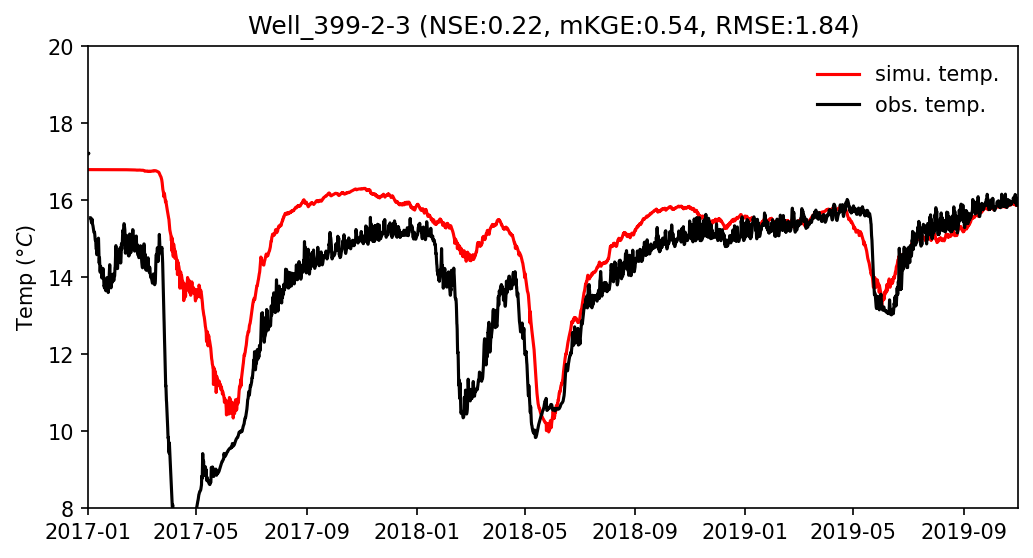

In [23]:
fig, isimu_df, iobs_df = plot_well_temp(iwell = 'Well_399-2-3', smooth_window='6H', flux_average=True, return_df=True)

### batch plot

In [ ]:
# for iwell in selected_obs_wells:
#     # fig = plot_well_temp(iwell)   
#     try:
#         fig = plot_well_temp(iwell, flux_average=True)
#     except:
#         pass
    
#     fig.savefig(figure_dir + f"{case_name}simu_obs_temp/" + iwell + '_2019.jpg', dpi=300)
#     plt.close(fig)

#### all in one

In [ ]:
well_list = [ 'Well_399-2-2','Well_399-1-16A','Well_399-1-21A','Well_399-1-7','Well_399-2-32','Well_399-2-3','Well_399-2-1']

In [ ]:
fig, axes = plt.subplots(4, 2, figsize = (12, 24))

for iwell, ax in zip(well_list, axes.flatten()[:-1]):
#     iwell = 'Well_399-2-2'
    isimu_head = well_data_df[iwell, 'Temperature [C]'].copy()
#     isimu_head = (isimu_head - P_atm) / rho / g_const
    isimu_head.dropna(axis = 1, inplace = True)

#     for i in isimu_head.columns:
#         isimu_head.loc[:, i] = isimu_head.loc[:, i] + obs_pts_df.loc[i, 'coord_z']

    simu_time = np.array([date_origin + timedelta(hours=i) for i in isimu_head.index])

    isimu_head['DateTime'] = simu_time
    isimu_head.set_index('DateTime', inplace=True)

    iobs_head =  obs_data_df[obs_data_df['WellName'] == iwell.replace('Well_', '')].sort_values(by = ['DateTime'])
    iobs_head = iobs_head[iobs_head['DateTime'].notnull()]
    iobs_head.set_index('DateTime', drop = False, inplace = True)
    
    merged_df = pd.merge(isimu_head, iobs_head, right_on = iobs_head.index ,left_index = True)
    merged_df.dropna(subset=[f'{iwell}_1', "Temp"], inplace=True)
    # rmse = mean_squared_error(merged_df.loc[:, f'{iwell}_1'], merged_df.loc[:, 'Temp'])**0.5
#     fig, ax = plt.subplots(1,1, figsize=(6,6))
    ax.plot(merged_df.index, merged_df.loc[:, f'{iwell}_1'], 'r-')
    ax.plot(merged_df.index,merged_df.loc[:, 'Temp'], 'k-')
#     sns.scatterplot(data = merged_df, x = f'{iwell}_1', y = "Temp", ax = ax)
#     ax.plot([0, 1], [0, 1], color='red', transform=ax.transAxes)
    # ax.text(0.7, 0.92, 'RMSE = {0:.2f}'.format(rmse), fontweight= 'bold',
    #      fontsize = 16, color = 'k', transform = ax.transAxes)
    
    ax.set_ylim([8, 20])
#     ax.legend(['simu_head', 'obs_head'])
    ax.set_title(iwell, fontsize = 20)
    ax.set_ylabel('Observed temperature (${\degree}C$)', fontsize = 16)
    ax.set_xlabel('Simulated temperature (${\degree}C$)', fontsize = 16)
    ax.set_aspect('auto')
    

axes[-1, -1].axis('off')
fig.tight_layout()

In [97]:
fig.savefig(out_dir + 'scatterplots/temp_allinone.png', dpi=300)
plt.close(fig)

#### one2one plot

In [ ]:
well_list = [ 'Well_399-2-2','Well_399-1-16A','Well_399-1-21A','Well_399-1-7','Well_399-2-32','Well_399-2-3','Well_399-2-1']

In [ ]:
fig, axes = plt.subplots(2, 4, figsize = (24, 12))

for iwell, ax in zip(well_list, axes.flatten()[:-1]):
#     iwell = 'Well_399-2-2'
    isimu_head = well_data_df[iwell, 'Temperature [C]'].copy()
#     isimu_head = (isimu_head - P_atm) / rho / g_const
    isimu_head.dropna(axis = 1, inplace = True)

#     for i in isimu_head.columns:
#         isimu_head.loc[:, i] = isimu_head.loc[:, i] + obs_pts_df.loc[i, 'coord_z']

    simu_time = np.array([date_origin + timedelta(hours=i) for i in isimu_head.index])

    isimu_head['DateTime'] = simu_time
    isimu_head.set_index('DateTime', inplace=True)

    iobs_head =  obs_data_df[obs_data_df['WellName'] == iwell.replace('Well_', '')].sort_values(by = ['DateTime'])
    iobs_head = iobs_head[iobs_head['DateTime'].notnull()]
    iobs_head.set_index('DateTime', drop = False, inplace = True)
    
    merged_df = pd.merge(isimu_head, iobs_head, right_on = iobs_head.index ,left_index = True)
    merged_df.dropna(subset=[f'{iwell}_1', "Temp"], inplace=True)
    rmse = mean_squared_error(merged_df.loc[:, f'{iwell}_1'], merged_df.loc[:, 'Temp'])**0.5
#     fig, ax = plt.subplots(1,1, figsize=(6,6))

    sns.scatterplot(data = merged_df, x = f'{iwell}_1', y = "Temp", ax = ax)
    ax.plot([0, 1], [0, 1], color='red', transform=ax.transAxes)
    ax.text(0.05, 0.85, 'RMSE = {0:.2f}'.format(rmse), fontweight= 'bold',
         fontsize = 16, color = 'k', transform = ax.transAxes)
    
#     ax.set_ylim([0, 24])
#     ax.legend(['simu_head', 'obs_head'])
    ax.set_title(iwell, fontsize = 20)
    ax.set_ylabel('Observed temperature (${\degree}C$)', fontsize = 16)
    ax.set_xlabel('Simulated temperature (${\degree}C$)', fontsize = 16)
    ax.set_aspect('auto')
    

axes[-1, -1].axis('off')
fig.tight_layout()

In [89]:
fig.savefig(out_dir + 'scatterplots/wl_one2one.png', dpi=300)
plt.close(fig)

### thermistors

#### Dense Array

In [24]:
piezometer_list = [i for i in well_data_df.columns.levels[0] if "Well_" not in i]

In [25]:
DA_wells = [i for i in piezometer_list if i.startswith('T')]

In [26]:
DA_T = pd.read_csv(fname_DA_T, na_values = ['NA', 'NAN'])
DA_T = insertNA(DA_T, 'TIMESTAMP')
DA_T.set_index('TIMESTAMP', drop = False, inplace = True)

In [34]:
def plot_DA_temp(iwell, smooth_window = None, flux_average = True, return_df = False, start_date = None, end_date = None):
    
    iwell_id = well_screen[well_screen['WellName'] == iwell]['Well_ID'].values[0]

    iobs_df = DA_T.loc[:, iwell_id.replace('(', '.').replace(')', '.')].copy()
    # use 6-hr smoothing for observationd data (5 min freq)
    if smooth_window is not None:
        iobs_df = iobs_df.resample(smooth_window).mean()
    iobs_df[iobs_df < 0] = np.nan
    # iobs_smooth = iobs_df.resample('6H', offset='3H').mean()
    isimu_df = well_data_df.loc[:, [(iwell,'Temperature [C]', 'flux_ave_temp')]].copy()
    
    # isimu_df = well_data_df[iwell,'Temperature [C]'].copy()
    # isimu_df = isimu_df.sort_index()
    
    simu_time = np.array([date_origin + timedelta(hours=i) for i in isimu_df.index])
    
    isimu_df['DateTime'] = pd.to_datetime(simu_time)
    isimu_df.set_index('DateTime', inplace=True)

    # iobs_df =  obs_data_df[obs_data_df['WellName'] == iwell.replace('Well_', '')].sort_values(by = ['DateTime'])
    # # iobs_df =  obs_data_df[obs_data_df['WellName'] == iwell].sort_values(by = ['DateTime'])
    # iobs_df = iobs_df[iobs_df['DateTime'].notnull()]
    # iobs_df.set_index('DateTime', drop = False, inplace = True)

    # if smooth_window is not None:
    #     # Apply rolling mean
    #     iobs_df = iobs_df.rolling(window=smooth_window).mean()

    # get metrics
    metric, _ = utils.get_metrics(iobs_df.index, iobs_df.values, isimu_df.index, isimu_df.iloc[:, -1].values, 
                     metrics=['NSE', 'mKGE', 'RMSE'])
    print(metric)
    
    fig, ax = plt.subplots(1,1, figsize=(8,4))

    ax.plot(iobs_df.index,iobs_df.values, 'k-')
    if flux_average:
        ax.plot(simu_time, isimu_df.iloc[:, -1], 'r-')
    else:
        ax.plot(simu_time, isimu_df.iloc[:, 0], 'r-')
    #     ax11 = ax.twinx()


    #     ax.legend(['simu. temp.', 'obs. temp.'],loc=[0.31, 1.01], frameon = False)

    # ax.set_xlim([iobs_df.index[0], iobs_df.index[-1]])
    # ax.set_xlim(['04/01/2017', '07/01/2019'])
    if start_date is None:
        # start_date = simu_time[0]
        start_date = iobs_df.index[0]
    if end_date is None:
        # end_date = simu_time[-1] 
        end_date = iobs_df.index[-1]
    ax.set_xlim([start_date, end_date])
    
    ax.set_ylim([0, 24])
    ax.legend(['Obs. temp.', 'Simu. temp.'],loc='best', frameon = False)
    # ax.set_title(iwell, fontsize = 16)
    ax.set_title(f"{iwell} (NSE:{metric['NSE']:.2f}, mKGE:{metric['mKGE']:.2f}, RMSE:{metric['RMSE']:.2f})", fontsize=16)
    ax.set_ylabel('Temperature $(^{\circ}C)$', fontsize=16)
    # ax.set_ylabel('Temp (${\degree}C$)')    
    
    if return_df:
        return fig, isimu_df, iobs_df
    else:
        return fig

{'NSE': 0.6912668204949215, 'mKGE': 0.7467434244537474, 'RMSE': 1.8586778722709911}


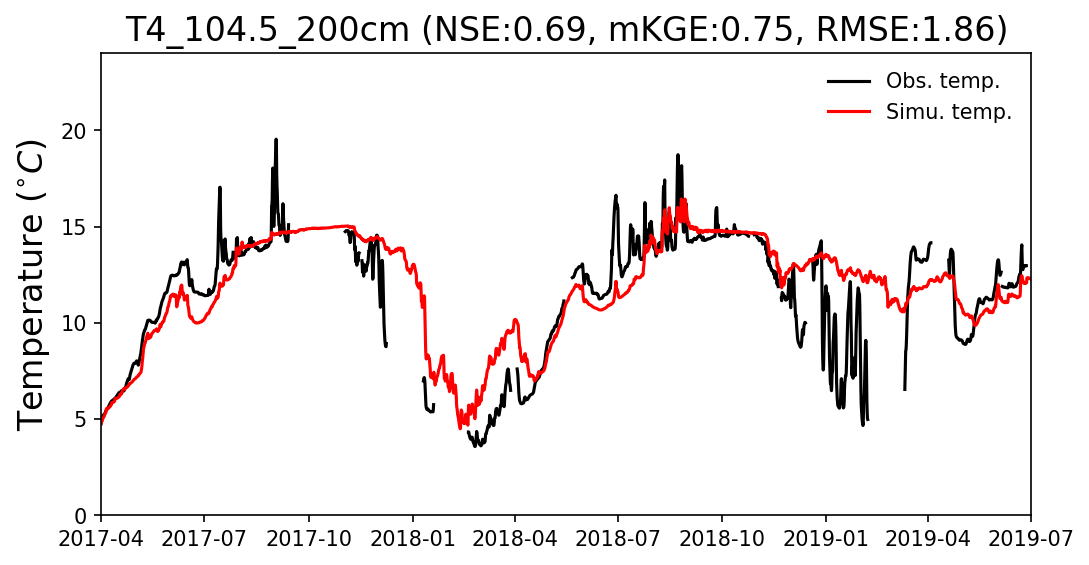

In [37]:
iwell = 'T4_104.5_200cm'
fig, isimu_df, iobs_df = plot_DA_temp(iwell = iwell, smooth_window='6H', flux_average=True, return_df=True, start_date="04/01/2017", end_date="07/01/2019")

In [39]:
fig.savefig(f"../figures/simu_obs_temp/hete_{iwell}.jpg", dpi=300)
plt.close(fig)  

In [40]:
for iwell in tqdm(DA_wells):
    fig = plot_DA_temp(iwell = iwell, smooth_window='6H', flux_average=True, start_date="04/01/2017", end_date="07/01/2019")
    fig.savefig(f"../figures/simu_obs_temp/hete_{iwell}.jpg", dpi=300)
    plt.close(fig)  

  0%|          | 0/50 [00:00<?, ?it/s]

{'NSE': 0.7681622721195147, 'mKGE': 0.8563414841899127, 'RMSE': 2.0827357467136394}
{'NSE': 0.7693616563837788, 'mKGE': 0.8832489012682525, 'RMSE': 1.8327244596523067}
{'NSE': 0.8306880992454536, 'mKGE': 0.9184801190645975, 'RMSE': 1.3103056484696833}
{'NSE': 0.8132622166181223, 'mKGE': 0.9045271375172966, 'RMSE': 1.631252971759898}
{'NSE': 0.6942981502773592, 'mKGE': 0.7693262096746953, 'RMSE': 2.208990744604539}
{'NSE': 0.7366910975663237, 'mKGE': 0.7623782370051578, 'RMSE': 2.421764679903314}
{'NSE': 0.6929414159781371, 'mKGE': 0.7555840614188541, 'RMSE': 2.2127049489401136}
{'NSE': 0.8302081691509708, 'mKGE': 0.9155630110228955, 'RMSE': 1.6590898446788862}
{'NSE': 0.8339896672517096, 'mKGE': 0.8810925226625079, 'RMSE': 1.7577696778103693}
{'NSE': 0.8361218358518674, 'mKGE': 0.8931688025422957, 'RMSE': 1.7060839422728697}
{'NSE': 0.667036402877602, 'mKGE': 0.7172961539909748, 'RMSE': 2.5145667647155636}
{'NSE': 0.719369664911914, 'mKGE': 0.7257736706703943, 'RMSE': 2.613954156254345

In [ ]:
# tube_list = ['Well_T5_105.5_54cm','Well_T5_105.5_100cm','Well_T5_105.5_200cm']


# fig, axes = plt.subplots(1,3, figsize=(18,6))

# for iwell, ax in zip(tube_list, axes.flatten()):
# #     iwell = 'Well_T1_104.5_45cm'
#     iwell_id = well_screen[well_screen['WellName'] == iwell.replace('Well_', '')]['Well_ID'].values[0]

#     iobs_df = DA_T.loc[:, iwell_id.replace('(', '.').replace(')', '.')]
#     isimu_df = well_data_df[iwell,'Temperature [C]', 'flux_ave_temp'].copy()

# #     fig, ax = plt.subplots(1,1, figsize=(8,6))

#     ax.plot(river_temp.index, river_temp['temp'],color = 'gray', alpha = 0.5, lw = 0.5)
#     # river_temp.plot(y = 'temp', ax=ax, color = 'gray', alpha = 0.5, lw = 0.5)
    
#     ax.plot(iobs_df.index,iobs_df.values, 'k-', lw=0.5)
#     ax.plot(simu_time, isimu_df.values, 'r-', lw=0.5)
#     # DA_cell_temp.plot(color='black', ax=ax)

#     ax.set_ylabel('Temperature $(^{\circ}C)$', fontsize=16)
#     ax.set_xlabel('')
#     ax.set_xlim([pd.Timestamp('2017-01-01'), pd.Timestamp('01/01/2019')])
#     ax.set_ylim([1, 24])
#     # ax.xaxis.set_major_locator(mdates.YearLocator())
#     # ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
#     # ax.xaxis.set_tick_params('labelbottom')
#     fig.autofmt_xdate()

#     # ax.tick_params(axis='both', which='major', labelsize=14)

#     ax.legend(['river temp.','obs. temp.','simu. temp.'], loc='best')
#     ax.set_title(iwell, fontsize=16)
    
# #     fig.savefig(fname_simu_obs_temp + iwell + '.png', dpi=300)
# #     plt.close(fig)

# fig.savefig(out_dir + 'scatterplots/T5_105.5_temp_allinone.png', dpi=300)
# plt.close(fig)

#### iButton

Because of the small interval in some iButton screen, the simulated temp maybe from the same nearest cell. Need to increase model vertical resolution.

In [41]:
metadata = pd.read_csv(iButton_dir + 'iButton_b1_to_d6_Summary.csv')

In [42]:
all_files = glob.glob(iButton_dir + '*.csv')

In [43]:
logger = 'b'
logger_files = [i for i in all_files if logger == i[-6] ]
logger_files = natsorted(logger_files)

In [44]:
iButton_wells = [i for i in piezometer_list if 'iButton' in i]

In [45]:
def plot_iButton_temp(iwell, smooth_window = None, flux_average = True, return_df = False, start_date = None, end_date = None):

#     iwell = iButton_wells[0]
    iwell_id = well_screen[well_screen['WellName'] == iwell]['Well_ID'].values[0]
    iwell_name = metadata[metadata['Name'] == iwell_id.replace('iButton', 'Zhou')]['Represent Name'].values[0]

    ilogger = [i for i in logger_files if iwell_name in i][0]

    # fig, ax = plt.subplots(1,1, figsize=(8,6))

    # isimu_df = well_data_df[iwell,'Temperature [C]', 'flux_ave_temp'].copy()
    
    # labels = ['river temperature']
    # for ifile in logger_files[2:]:
    iobs_df = pd.read_csv(ilogger, skiprows=1, names=['datetime', 'temp'])
    iobs_df = insertNA(iobs_df, 'datetime')
    # # use 6-hr smoothing for observationd data (5 min freq)
    iobs_df['datetime'] = pd.to_datetime(iobs_df['datetime'])
    iobs_df.set_index('datetime', inplace=True)
    if smooth_window is not None:
        iobs_df = iobs_df.resample(smooth_window).mean()
    
    # print(iobs_df.head())

    #     df.rename(columns={'# Datetime': 'datetime'}, inplace = True)

    isimu_df = well_data_df.loc[:, [(iwell,'Temperature [C]', 'flux_ave_temp')]].copy()
    
    # iwell_id = well_screen[well_screen['WellName'] == iwell]['Well_ID'].values[0]
    
    simu_time = np.array([date_origin + timedelta(hours=i) for i in isimu_df.index])
    
    isimu_df['DateTime'] = pd.to_datetime(simu_time)
    isimu_df.set_index('DateTime', inplace=True)

    # if smooth_window is not None:
    #     # Apply rolling mean
    #     iobs_df = iobs_df.rolling(window=smooth_window).mean()

    # get metrics
    metric, _ = utils.get_metrics(iobs_df.index, iobs_df.iloc[:, 0].values, isimu_df.index, isimu_df.iloc[:, -1].values, 
                     metrics=['NSE', 'mKGE', 'RMSE'])
    print(metric)
    
    fig, ax = plt.subplots(1,1, figsize=(8,4))

    ax.plot(iobs_df.index,iobs_df.values, 'k-')
    if flux_average:
        ax.plot(simu_time, isimu_df.iloc[:, -1], 'r-')
    else:
        ax.plot(simu_time, isimu_df.iloc[:, 0], 'r-')

    if start_date is None:
        start_date = simu_time[0]
    if end_date is None:
        end_date = simu_time[-1]        
    
    ax.set_xlim([start_date, end_date])
    ax.set_ylim([0, 24])
    ax.legend(['obs. temp.', 'simu. temp.'],loc='best', frameon = False)
    # ax.set_title(iwell, fontsize = 16)
    ax.set_title(f"{iwell} (NSE:{metric['NSE']:.2f}, mKGE:{metric['mKGE']:.2f}, RMSE:{metric['RMSE']:.2f})", fontsize=16)
    ax.set_ylabel('Temperature $(^{\circ}C)$', fontsize=16)
    # ax.set_ylabel('Temp (${\degree}C$)')    
    
    if return_df:
        return fig, isimu_df, iobs_df
    else:
        return fig

{'NSE': -0.9483117656646671, 'mKGE': -0.09904397064612791, 'RMSE': 3.333637313146363}


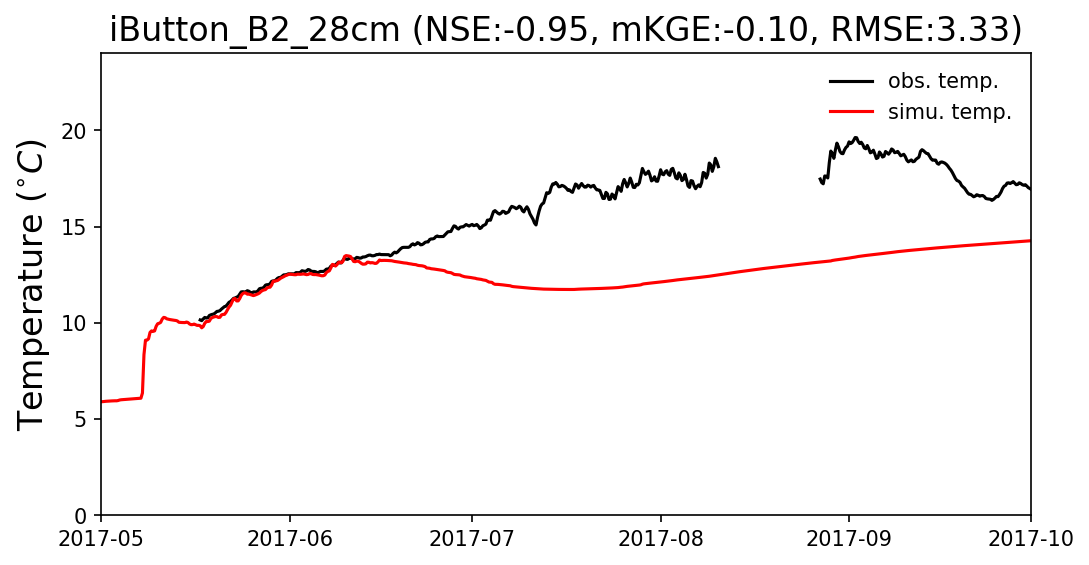

In [47]:
fig, isimu_df, iobs_df = plot_iButton_temp(iwell = 'iButton_B2_28cm', smooth_window='6H', flux_average=True, return_df=True, start_date="05/01/2017", end_date="10/01/2017")

{'NSE': -1.126888741739632, 'mKGE': -0.2933515734432779, 'RMSE': 3.9520086182205203}


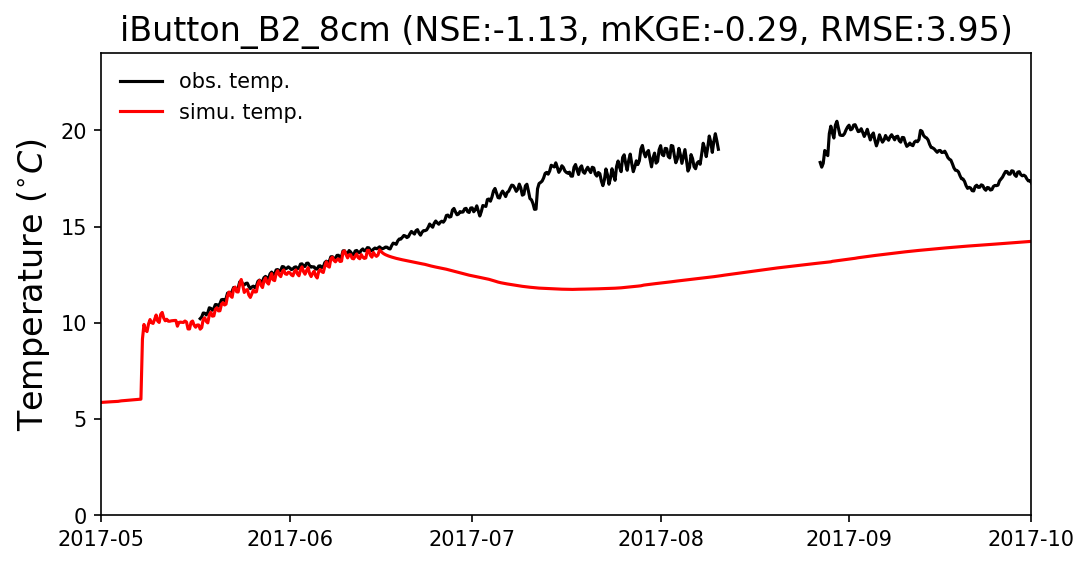

In [48]:
fig, isimu_df, iobs_df = plot_iButton_temp(iwell = 'iButton_B2_8cm', smooth_window='6H', flux_average=True, return_df=True,  start_date="05/01/2017", end_date="10/01/2017")

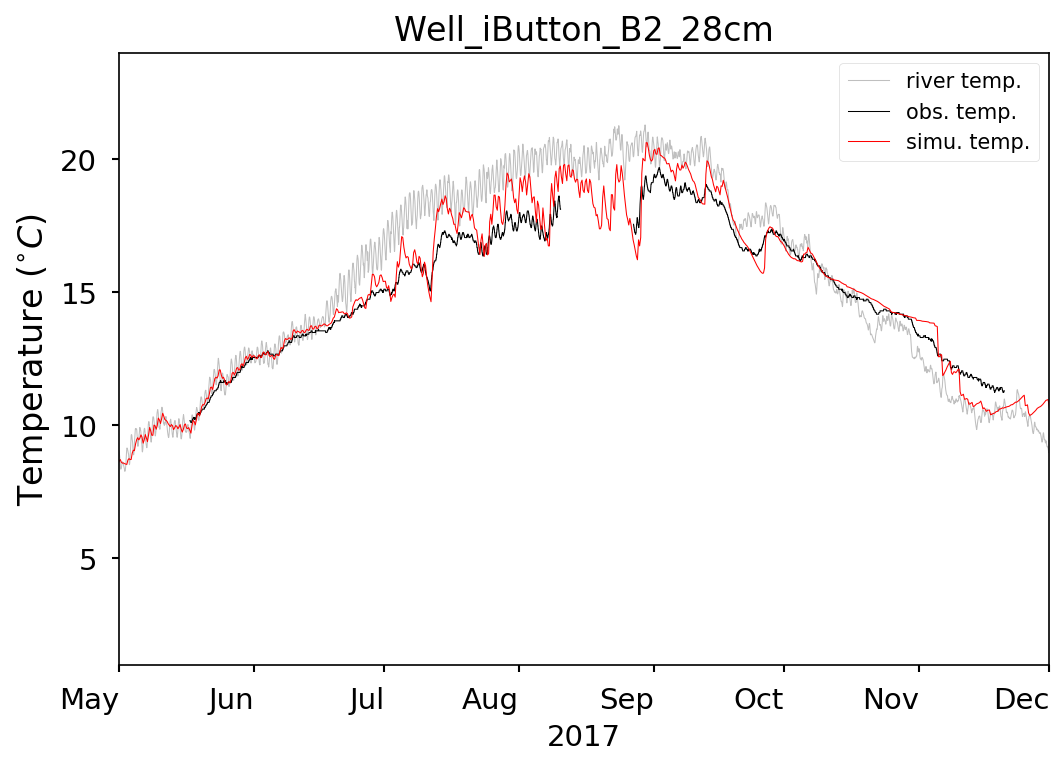

In [97]:
# is the plot generated from the 400m AT model?

#### RG3_T3

In [49]:
RG3_T = pd.read_csv(fname_RG3_T, na_values = ['NAN'])
RG3_T.dropna(subset=['time'], inplace=True)
RG3_T = insertNA(RG3_T, 'time')
RG3_T.set_index('time', drop=True, inplace=True)

In [50]:
RG3_smooth = RG3_T.resample('6H').mean()

In [51]:
RG3_wells = [i for i in piezometer_list if 'RG3' in i]

In [59]:
RG3_wells

['RG3_T3_24cm', 'RG3_T3_64cm']

In [61]:
def plot_RG3_temp(iwell, depth, start_date=None, end_date=None, return_df=False):
    
    isimu_df = well_data_df.loc[:, [(iwell, 'Temperature [C]', 'flux_ave_temp')]].copy()
    simu_time = np.array([date_origin + timedelta(hours=i) for i in isimu_df.index])
    
    isimu_df['DateTime'] = pd.to_datetime(simu_time)
    isimu_df.set_index('DateTime', inplace=True)
    isimu_df = isimu_df[isimu_df.index >= '2017-01-10']

    iobs_df = RG3_smooth[depth]

    # get metrics
    metric, _ = utils.get_metrics(iobs_df.index, iobs_df.values, isimu_df.index, isimu_df.iloc[:, -1].values,
                                  metrics=['NSE', 'mKGE', 'RMSE'])
    print(metric)

    fig, ax = plt.subplots(1, 1, figsize=(8, 4))
    ax.plot(iobs_df.index, iobs_df.values, 'k-')
    ax.plot(isimu_df.index, isimu_df.iloc[:, -1], 'r-')
    ax.set_ylabel('Temperature $(^{\circ}C)$', fontsize=16)
    ax.set_xlabel('')

    if start_date is None:
        start_date = pd.Timestamp('2017-01-10')
    if end_date is None:
        end_date = pd.Timestamp('2018-05-01')
    ax.set_xlim([start_date, end_date])

    ax.set_ylim([0, 24])
    ax.legend(['Obs. temp.', 'Simu. temp.'], loc='best', frameon=False)
    ax.set_title(f"{iwell} (NSE:{metric['NSE']:.2f}, mKGE:{metric['mKGE']:.2f}, RMSE:{metric['RMSE']:.2f})", fontsize=16)

    if return_df:
        return fig, isimu_df, iobs_df
    else:
        return fig

{'NSE': 0.8699264476602678, 'mKGE': 0.9333558679795231, 'RMSE': 1.9129964156511352}


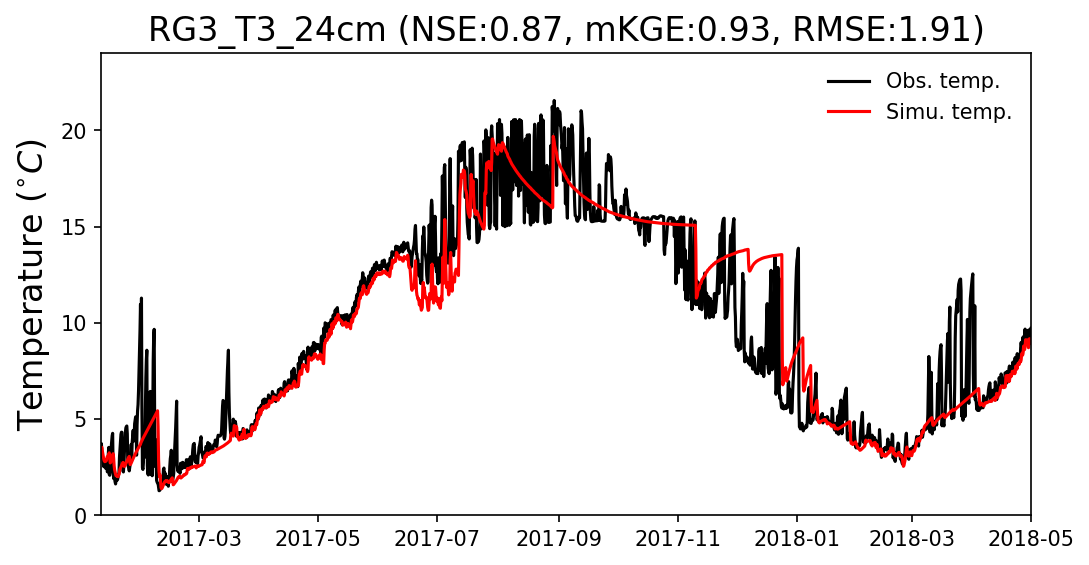

In [62]:
fig = plot_RG3_temp(iwell='RG3_T3_24cm', depth="mid")

In [63]:
fig.savefig(f"../figures/simu_obs_temp/hete_{iwell}.jpg", dpi=300)
plt.close(fig)

{'NSE': 0.8281166402575051, 'mKGE': 0.8798835657591557, 'RMSE': 2.1268256949365267}


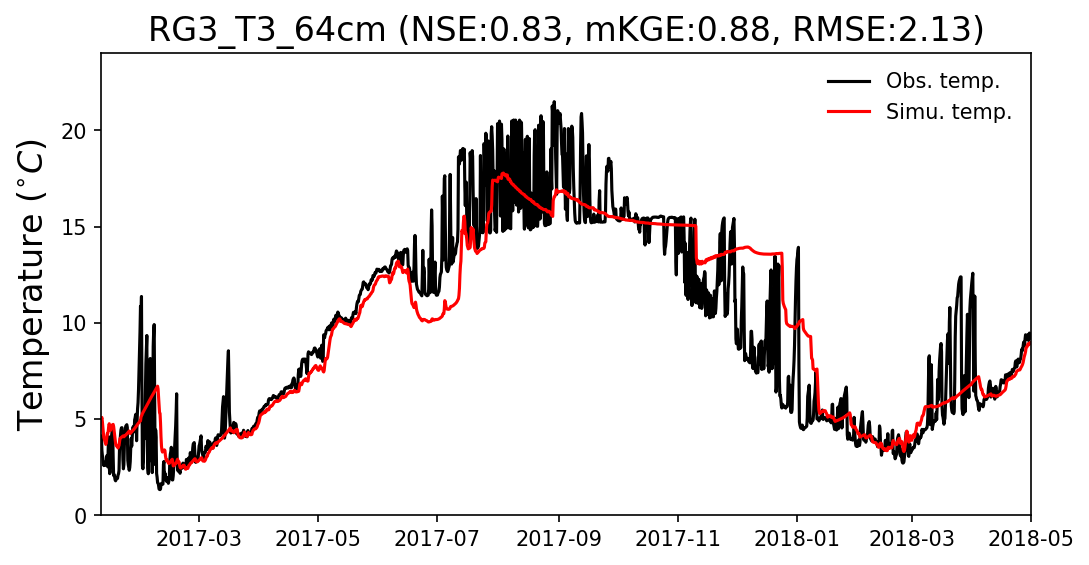

In [64]:
fig = plot_RG3_temp(iwell='RG3_T3_64cm', depth="bot")

In [65]:
fig.savefig(f"../figures/simu_obs_temp/hete_{iwell}.jpg", dpi=300)
plt.close(fig)

## Hete vs homo cases